In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
from pathlib import Path
from scipy.fft import dct, idct
import numpy as np
from sklearn.neighbors import LocalOutlierFactor
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.data_loader import load_reservoir_data
from statsmodels.tsa.seasonal import STL
from scipy.signal import stft



2026-11-07 16:38:15.839 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


# Loading and looking at shapefiles

In [9]:
# Load shapefiles
gdf_regions = gpd.read_file("../data/shapefiles/nve_region/NVE_Region.shp")
gdf_zones = gpd.read_file("../data/shapefiles/bidding_zones/biddingzones.shp")

print("NVE regions:")
print(gdf_regions.head())
print(gdf_regions.crs)

print("Bidding zones:")
print(gdf_zones.head())
print(gdf_zones.crs)

NVE regions:
   OBJECTID REGION         REGIONNAVN POSTNUMMER   POSTSTED  \
0       1.0     RV        Region Vest       6801     FÃ¸rde   
1       2.0     RM  Region Midt-Norge       7030  Trondheim   
2       3.0     RN        Region Nord       8514     Narvik   
3       4.0    RÃ        Region Ãst       2307      Hamar   
4       5.0     RS        Region SÃ¸r       3103  TÃ¸nsberg   

               BESÃKSADR            ADRESSE  \
0       Naustdalsveien 1B        Postboks 53   
1  Abelsgate 9, Trondheim        Abelsgate 9   
2       Kongensgate 52-54  Kongensgate 52-54   
3           Vangsvegen 73      Postboks 4223   
4   Anton Jenssens gate 7      Postboks 2124   

                                            geometry  
0  POLYGON ((193105.76 6929797.839, 191705.75 692...  
1  POLYGON ((391250 7388620, 392270 7386790, 3937...  
2  POLYGON ((1109096.413 7844647.502, 1105115.343...  
3  POLYGON ((253748.22 6678130.91, 253645.58 6678...  
4  POLYGON ((253748.22 6678130.91, 253917.63

# Generate random coordinates

In [11]:
# Number of random points per region
K = 10

# NVE regions
points_nve = gdf_regions["geometry"].sample_points(
    size=K, random_state=42
)

# Electricity bidding zones
points_zones = gdf_zones["geometry"].sample_points(
    size=K, random_state=42
)

#onvert points to correct format 
points_nve_wgs84 = points_nve.to_crs(epsg=4326)
points_zones_wgs84 = points_zones.to_crs(epsg=4326)

# Store coordinates by region
nve_coordinates = {}
zone_coordinates = {}

for idx, multipoint in points_nve_wgs84.items():
    region = gdf_regions.loc[idx, "REGION"]

    nve_coordinates[region] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        nve_coordinates[region].append((lon, lat))


for idx, multipoint in points_zones_wgs84.items():
    zone = gdf_zones.loc[idx, "budomr"]

    zone_coordinates[zone] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        zone_coordinates[zone].append((lon, lat))

print("NVE regions:")
for region, coordinates in nve_coordinates.items():
    print(region, len(coordinates), coordinates[:2])

print("Bidding zones:")
for zone, coordinates in zone_coordinates.items():
    print(zone, len(coordinates), coordinates[:2])

print("NO3 coordinates:", len(zone_coordinates["NO 3"]))
print("First coordinate:", zone_coordinates["NO 3"][0])

NVE regions:
RV 10 [(5.909274834494518, 61.367183376441986), (6.831127554063043, 59.81138679678551)]
RM 10 [(14.397395836724769, 65.52332689219718), (13.175737776421322, 65.6516015560037)]
RN 10 [(26.592056484098716, 70.75025296561303), (24.793146374699052, 68.67904404275)]
RÃ 10 [(7.665745140971847, 61.8161427014052), (10.393694000123714, 61.17412335410167)]
RS 10 [(5.721718785616444, 59.528106127990625), (6.279911310359943, 59.405978306635454)]
Bidding zones:
NO 1 10 [(10.54816324631569, 59.8339636056128), (11.146721959131847, 61.459765419451166)]
NO 2 10 [(10.52082077771421, 59.36906786316779), (4.637967875431399, 59.30223119329296)]
NO 3 10 [(5.061227240792199, 61.49620699415908), (11.416260057382182, 64.81981380181783)]
NO 4 10 [(25.913179300243502, 70.86624446273782), (16.95789156477844, 69.13201279306126)]
NO 5 10 [(8.187788079120041, 60.366224112488936), (5.387098935864515, 60.2610909618786)]
NO3 coordinates: 10
First coordinate: (5.061227240792199, 61.49620699415908)


# Set up Open-Meteo API Client

In [ ]:
# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession(".cache", expire_after=3600)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Select one random coordinate from NO3
lon, lat = zone_coordinates["NO 3"][0]

# Historical Weather API using ERA5 reanalysis
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": lat,
    "longitude": lon,
    "start_date": "2024-01-01",
    "end_date": "2024-01-07",
    "hourly": ["temperature_2m", "precipitation"],
    "models": "era5",
    "timezone": "GMT"
}

responses = openmeteo.weather_api(url, params=params)

# Process first location
response = responses[0]

print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data
# Variable order must match the order requested in params
hourly = response.Hourly()

hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()

hourly_data = {
    "date": pd.date_range(
        start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
        end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
        freq=pd.Timedelta(seconds=hourly.Interval()),
        inclusive="left"
    )
}

hourly_data["temperature_2m"] = hourly_temperature_2m
hourly_data["precipitation"] = hourly_precipitation

# Convert to Pandas DataFrame
df_weather = pd.DataFrame(data=hourly_data)

print("Hourly data:")
display(df_weather.head())

# Check dimensions, missing values and descriptive statistics
print("Shape:", df_weather.shape)
print("Missing values:")
print(df_weather.isna().sum())

display(df_weather.describe())

# Creating reusable function
Making the api call a function which takes regional identifier and time interval as input. Also includes batching to reduce the HTTP overhead.

In [ ]:
from pathlib import Path

def download_weather(region, start_date, end_date):
    """
    Download hourly ERA5 weather data for all sampled coordinates
    in a region, saving each completed batch as a CSV file.
    """

    # Look up sampled coordinates for the selected region
    coordinates = zone_coordinates[region]
    url = "https://archive-api.open-meteo.com/v1/archive"

    batch_size = 10
    weather_data = []

    # Create folder for the selected region and time interval
    folder = Path("../data/weather") / f"{region.replace(' ', '')}_{start_date}_{end_date}test10"
    folder.mkdir(parents=True, exist_ok=True)

    # Loop through coordinates in batches of 10
    for i in range(0, len(coordinates), batch_size):

        batch = coordinates[i:i + batch_size]
        batch_file = folder / f"batch_{i:04d}.csv"

        # Load previously downloaded batches
        if batch_file.exists():
            print(f"Loading saved batch {i}")
            df = pd.read_csv(batch_file, parse_dates=["date"])
            weather_data.append(df)
            continue

        # Extract latitude and longitude lists
        longitudes = [lon for lon, lat in batch]
        latitudes = [lat for lon, lat in batch]

        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
            "timezone": "GMT"
        }

        # Download weather data for the batch
        responses = openmeteo.weather_api(url, params=params)

        batch_data = []

        # Process each location in the batch
        for j, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            # Construct DataFrame
            df = pd.DataFrame({
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left"
                ),
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            # Add location information
            lon, lat = batch[j]

            df["region"] = region
            df["location_id"] = i + j
            df["latitude"] = lat
            df["longitude"] = lon

            batch_data.append(df)

        # Combine data from the current batch
        df_batch = pd.concat(batch_data, ignore_index=True)

        # Save completed batch as CSV
        df_batch.to_csv(batch_file, index=False)

        weather_data.append(df_batch)

        print(
            f"Saved {min(i + batch_size, len(coordinates))} "
            f"/ {len(coordinates)} locations"
        )

    # Combine all batches into one DataFrame
    return pd.concat(weather_data, ignore_index=True)

In [12]:
df_weather = download_weather(
    "NO 3",
    "2024-01-01",
    "2024-12-31"
)

Loading saved batch 0


In [ ]:
print("Shape:", df_weather.shape)

print("Unique locations:")
print(df_weather["location_id"].nunique())

print("Date range:")
print(df_weather["date"].min())
print(df_weather["date"].max())

print("Missing values:")
print(df_weather.isna().sum())

display(df_weather.head())

Shape: (87840, 7)
Unique locations:
10
Date range:
2024-01-01 00:00:00+00:00
2024-12-31 23:00:00+00:00
Missing values:
date              0
temperature_2m    0
precipitation     0
region            0
location_id       0
latitude          0
longitude         0
dtype: int64


,date,temperature_2m,precipitation,region,location_id,latitude,longitude
0,2024-01-01 00:00:00+00:00,-9.887,0.0,NO 3,0,63.408583,11.990562
1,2024-01-01 01:00:00+00:00,-9.837,0.0,NO 3,0,63.408583,11.990562
2,2024-01-01 02:00:00+00:00,-9.587,0.0,NO 3,0,63.408583,11.990562
3,2024-01-01 03:00:00+00:00,-9.437,0.0,NO 3,0,63.408583,11.990562
4,2024-01-01 04:00:00+00:00,-9.387,0.0,NO 3,0,63.408583,11.990562


In [ ]:
df_average = (
    df_weather
    .groupby("date")[["temperature_2m", "precipitation"]]
    .mean()
    .reset_index()
)

display(df_average.head())

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-5.68355,0.0
1,2024-01-01 01:00:00+00:00,-5.73855,0.0
2,2024-01-01 02:00:00+00:00,-5.61855,0.0
3,2024-01-01 03:00:00+00:00,-5.54355,0.0
4,2024-01-01 04:00:00+00:00,-5.48355,0.0


# Same for 1000 points
Doing the exact same thing just for K = 1000 points.

In [13]:
# Number of random points per region
K = 1000

# NVE regions
points_nve = gdf_regions["geometry"].sample_points(
    size=K, random_state=42
)

# Electricity bidding zones
points_zones = gdf_zones["geometry"].sample_points(
    size=K, random_state=42
)

points_nve_wgs84 = points_nve.to_crs(epsg=4326)
points_zones_wgs84 = points_zones.to_crs(epsg=4326)

# Store coordinates by region
nve_coordinates = {}
zone_coordinates = {}

for idx, multipoint in points_nve_wgs84.items():
    region = gdf_regions.loc[idx, "REGION"]

    nve_coordinates[region] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        nve_coordinates[region].append((lon, lat))


for idx, multipoint in points_zones_wgs84.items():
    zone = gdf_zones.loc[idx, "budomr"]

    zone_coordinates[zone] = []

    for point in multipoint.geoms:
        lat = point.y
        lon = point.x

        zone_coordinates[zone].append((lon, lat))

print("NVE regions:")
for region, coordinates in nve_coordinates.items():
    print(region, len(coordinates), coordinates[:2])

print("\nBidding zones:")
for zone, coordinates in zone_coordinates.items():
    print(zone, len(coordinates), coordinates[:2])

print("NO3 coordinates:", len(zone_coordinates["NO 3"]))
print("First coordinate:", zone_coordinates["NO 3"][0])

NVE regions:
RV 1000 [(4.910072169345388, 61.63229347663958), (5.98543875202532, 61.29524284085734)]
RM 1000 [(14.437040009474474, 65.51661007631229), (12.37672327553149, 66.20946844198176)]
RN 1000 [(18.372850009721542, 68.83694618489714), (26.15820191989615, 71.3173820647041)]
RÃ 1000 [(9.10210135979519, 61.75045152419467), (10.715057439828543, 62.6029889772636)]
RS 1000 [(8.348936424471592, 60.37851257163435), (6.603250599619637, 59.311599188855205)]

Bidding zones:
NO 1 1000 [(9.533547001384653, 61.6450970875047), (11.83217320171761, 59.872793851812126)]
NO 2 1000 [(9.880272874572785, 59.34185378948918), (6.199135295927724, 60.05147987558605)]
NO 3 1000 [(7.979686612524057, 63.78944363954876), (9.93687523654325, 63.779742344171815)]
NO 4 1000 [(14.435665752736616, 68.551522686423), (12.442878660078433, 67.9290340721872)]
NO 5 1000 [(7.2594156284459785, 61.44863530844993), (7.518279704977707, 60.39975046380239)]
NO3 coordinates: 1000
First coordinate: (7.979686612524057, 63.7894436

In [7]:
import json
from pathlib import Path

path = Path("../data/weather/zone_coordinates.json")
path.parent.mkdir(parents=True, exist_ok=True)

with open(path, "w") as f:
    json.dump(zone_coordinates, f)

print("Coordinates saved successfully!")

Coordinates saved successfully!


In [5]:
def download_weather(region, start_date, end_date):
    """
    Download hourly ERA5 weather data for all sampled coordinates
    in a region, saving each completed batch as a CSV file.
    """

    # Look up sampled coordinates for the selected region
    coordinates = zone_coordinates[region]
    url = "https://archive-api.open-meteo.com/v1/archive"

    batch_size = 100
    weather_data = []

    # Create folder for the selected region and time interval
    folder = Path("../data/weather") / f"{region.replace(' ', '')}_{start_date}_{end_date}"
    folder.mkdir(parents=True, exist_ok=True)

    # Loop through coordinates in batches of 10
    for i in range(0, len(coordinates), batch_size):

        batch = coordinates[i:i + batch_size]
        batch_file = folder / f"batch_{i:04d}.csv"

        # Load previously downloaded batches
        if batch_file.exists():
            print(f"Loading saved batch {i}")
            df = pd.read_csv(batch_file, parse_dates=["date"])
            weather_data.append(df)
            continue

        # Extract latitude and longitude lists
        longitudes = [lon for lon, lat in batch]
        latitudes = [lat for lon, lat in batch]

        params = {
            "latitude": latitudes,
            "longitude": longitudes,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": ["temperature_2m", "precipitation"],
            "models": "era5",
            "timezone": "GMT"
        }

        # Download weather data for the batch
        responses = openmeteo.weather_api(url, params=params)

        batch_data = []

        # Process each location in the batch
        for j, response in enumerate(responses):

            hourly = response.Hourly()

            temperature = hourly.Variables(0).ValuesAsNumpy()
            precipitation = hourly.Variables(1).ValuesAsNumpy()

            # Construct DataFrame
            df = pd.DataFrame({
                "date": pd.date_range(
                    start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                    end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                    freq=pd.Timedelta(seconds=hourly.Interval()),
                    inclusive="left"
                ),
                "temperature_2m": temperature,
                "precipitation": precipitation
            })

            # Add location information
            lon, lat = batch[j]

            df["region"] = region
            df["location_id"] = i + j
            df["latitude"] = lat
            df["longitude"] = lon

            batch_data.append(df)

        # Combine data from the current batch
        df_batch = pd.concat(batch_data, ignore_index=True)

        # Save completed batch as CSV
        df_batch.to_csv(batch_file, index=False)

        weather_data.append(df_batch)

        print(
            f"Saved {min(i + batch_size, len(coordinates))} "
            f"/ {len(coordinates)} locations"
        )

    # Combine all batches into one DataFrame
    return pd.concat(weather_data, ignore_index=True)

In [14]:
df_weather = download_weather(
    "NO 3",
    "2024-01-01",
    "2024-12-31"
)

Loading saved batch 0
Loading saved batch 100
Loading saved batch 200
Loading saved batch 300
Loading saved batch 400
Loading saved batch 500
Loading saved batch 600
Loading saved batch 700
Loading saved batch 800
Loading saved batch 900


# Saving regional hourly averages
Makes it easier to work with considering DCT/SPC and LOF.

In [2]:
def aggregate_weather(df, region, start_date, end_date):
    """
    Calculate hourly regional averages for temperature and precipitation.
    Save the result as a CSV file.
    """

    df_average = (
        df.groupby("date")[["temperature_2m", "precipitation"]]
        .mean()
        .reset_index()
    )

    # Create output directory if needed
    output_dir = Path("data/weather")
    output_dir.mkdir(parents=True, exist_ok=True)

    # Save using region and date interval
    filename = f"{region}_{start_date}_{end_date}_average.csv"
    df_average.to_csv(output_dir / filename, index=False)

    return df_average

In [15]:
df_average_no1 = aggregate_weather(
    df_weather,
    region="NO1",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

display(df_average_no1.head())

,date,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-3.55961,0.003
1,2024-01-01 01:00:00+00:00,-3.70011,0.002
2,2024-01-01 02:00:00+00:00,-3.68261,0.002
3,2024-01-01 03:00:00+00:00,-3.71611,0.002
4,2024-01-01 04:00:00+00:00,-3.66861,0.002


In [ ]:
print("Locations:", df_weather["location_id"].nunique())
print("Hourly observations:", len(df_average))
print("Missing values:")
print(df_average.isna().sum())

Locations: 1000
Hourly observations: 8784
Missing values:
date              0
temperature_2m    0
precipitation     0
dtype: int64


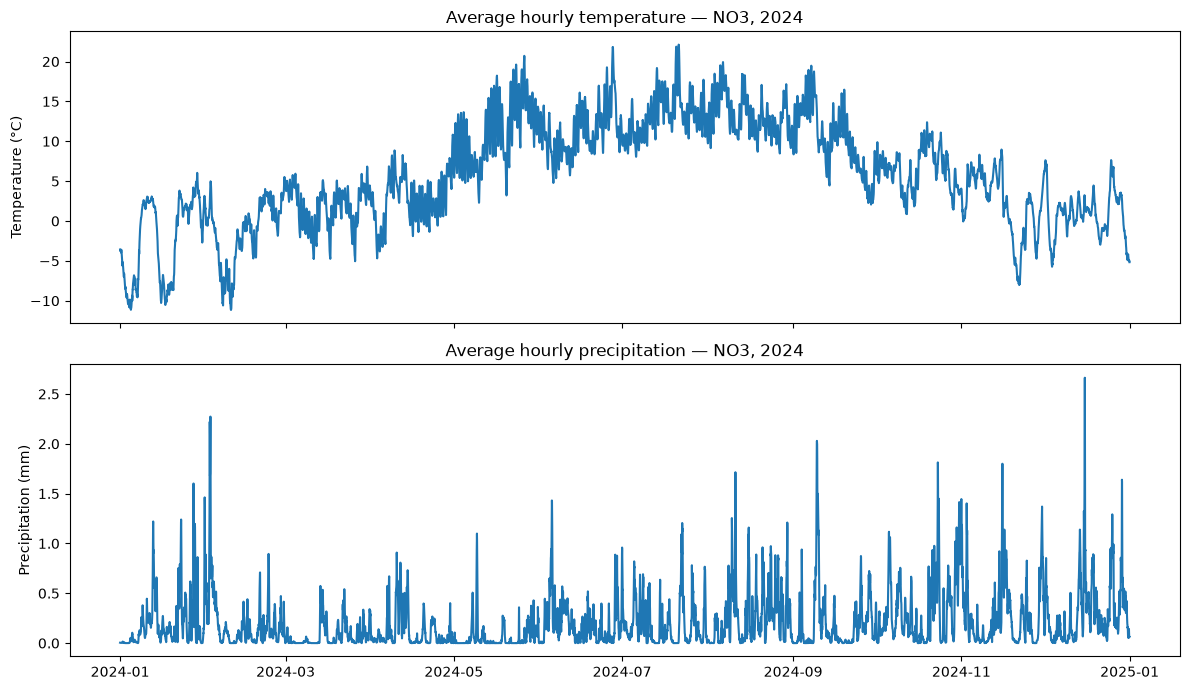

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df_average["date"], df_average["temperature_2m"])
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title("Average hourly temperature — NO3, 2024")

axes[1].plot(df_average["date"], df_average["precipitation"])
axes[1].set_ylabel("Precipitation (mm)")
axes[1].set_title("Average hourly precipitation — NO3, 2024")

plt.tight_layout()
plt.show()

# Converting to SATV using DCT
Converting the avg hrly precipitation to the SATV form using DCT

In [ ]:
# Extract average hourly precipitation
precipitation = df_average["precipitation"].values

# Apply Discrete Cosine Transform
fourier_signal = dct(precipitation, type=1, norm="forward")

# Remove low frequencies
cutoff = 30

filtered_fourier_signal = fourier_signal.copy()
filtered_fourier_signal[:cutoff] = 0

# Reconstruct the high-pass filtered signal
satv = idct(filtered_fourier_signal, type=1, norm="forward")

#

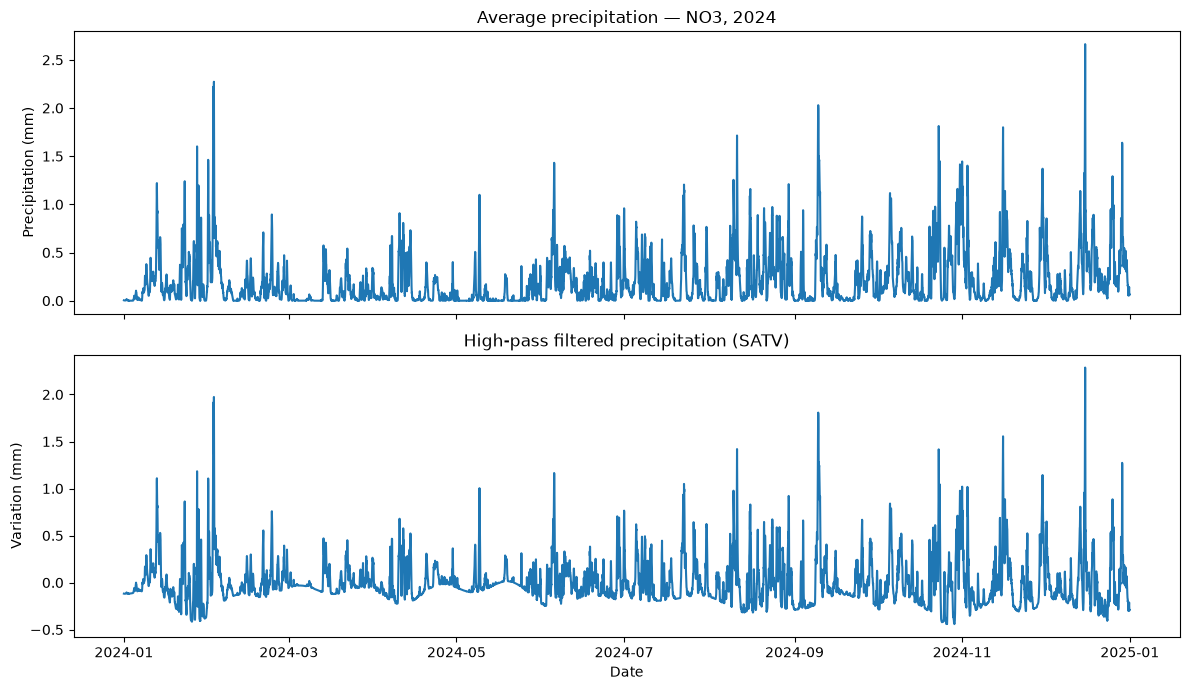

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(df_average["date"], precipitation)
axes[0].set_title("Average precipitation — NO3, 2024")
axes[0].set_ylabel("Precipitation (mm)")

axes[1].plot(df_average["date"], satv)
axes[1].set_title("High-pass filtered precipitation (SATV)")
axes[1].set_ylabel("Variation (mm)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

# Robust statistics
Using SPC with the SATV to find outliers

In [ ]:
# Robust statistics based on SATV
median_satv = np.median(satv)

mad = np.median(np.abs(satv - median_satv))
robust_std = 1.4826 * mad

# SPC boundaries
n_std = 3

lower_bound = median_satv - n_std * robust_std
upper_bound = median_satv + n_std * robust_std

# Identify outliers
outliers = (satv < lower_bound) | (satv > upper_bound)

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", outliers.sum())
print("Percentage of outliers:", 100 * outliers.mean())

Lower bound: -0.49739224
Upper bound: 0.38905185
Number of outliers: 613
Percentage of outliers: 6.978597449908926


# PLotting precipitation with outliers
Using SATV to plot the original values

In [ ]:
# Reconstruct the removed low-frequency component
baseline = precipitation - satv

# Transform SPC boundaries back to precipitation scale
lower_curve = baseline + lower_bound
upper_curve = baseline + upper_bound

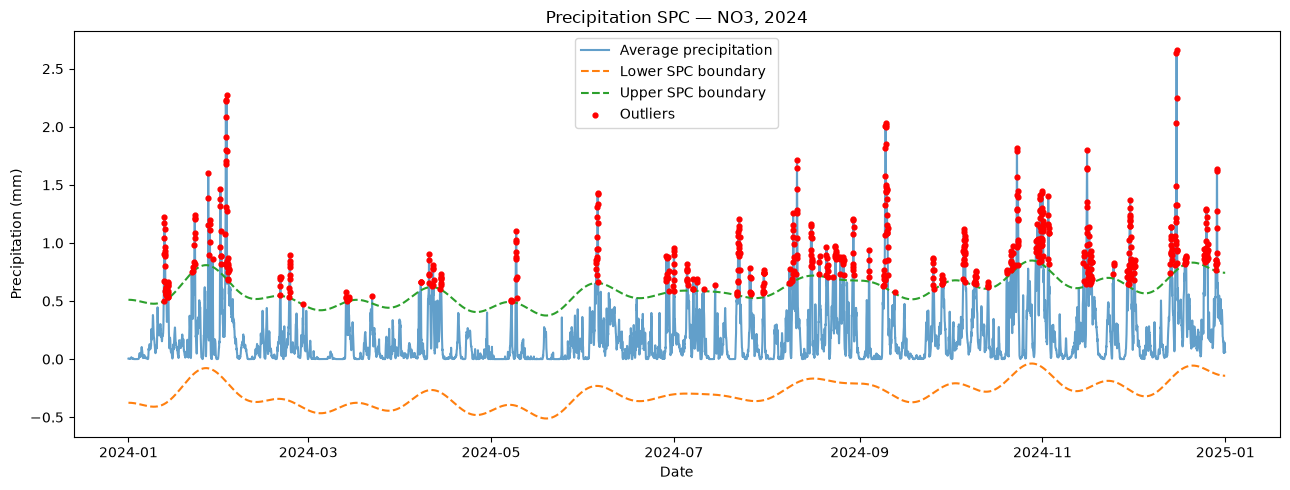

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    df_average["date"],
    precipitation,
    label="Average precipitation",
    alpha=0.7
)

ax.plot(
    df_average["date"],
    lower_curve,
    "--",
    label="Lower SPC boundary"
)

ax.plot(
    df_average["date"],
    upper_curve,
    "--",
    label="Upper SPC boundary"
)

ax.scatter(
    df_average.loc[outliers, "date"],
    precipitation[outliers],
    color="red",
    s=12,
    label="Outliers",
    zorder=3
)

ax.set_title("Precipitation SPC — NO3, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Precipitation (mm)")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
print("Median SATV:", median_satv)
print("Robust standard deviation:", robust_std)
print("Outlier percentage:", round(100 * outliers.mean(), 2), "%")

Median SATV: -0.054170184
Robust standard deviation: 0.14774068
Outlier percentage: 6.98 %


# Wrapping in a function

In [ ]:
def precipitation_spc(df, cutoff=30, n_std=3):
    """
    Detect precipitation outliers using DCT high-pass filtering
    and robust Statistical Process Control (SPC).

    Returns the plot and a summary of outliers.
    """

    # Extract precipitation data
    precipitation = df["precipitation"].to_numpy()
    dates = df["date"]

    # DCT high-pass filtering
    fourier_signal = dct(precipitation, type=1, norm="forward")

    filtered_signal = fourier_signal.copy()
    filtered_signal[:cutoff] = 0

    satv = idct(filtered_signal, type=1, norm="forward")

    # Robust statistics based on SATV
    median_satv = np.median(satv)
    mad = np.median(np.abs(satv - median_satv))
    robust_std = 1.4826 * mad

    # SPC boundaries
    lower_bound = median_satv - n_std * robust_std
    upper_bound = median_satv + n_std * robust_std

    # Identify outliers
    upper_outliers = satv > upper_bound
    lower_outliers = satv < lower_bound
    outliers = upper_outliers | lower_outliers

    # Transform boundaries back to precipitation scale
    baseline = precipitation - satv

    lower_curve = baseline + lower_bound
    upper_curve = baseline + upper_bound

    # Plot original precipitation and SPC boundaries
    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(dates, precipitation, label="Average precipitation", alpha=0.7)
    ax.plot(dates, lower_curve, "--", label="Lower SPC boundary")
    ax.plot(dates, upper_curve, "--", label="Upper SPC boundary")

    ax.scatter(
        dates[outliers],
        precipitation[outliers],
        color="red",
        s=12,
        label="Outliers",
        zorder=3
    )

    ax.set_title("Precipitation SPC — NO3, 2024")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()

    plt.tight_layout()

    # Outlier summary
    summary = {
        "total_observations": len(precipitation),
        "total_outliers": int(outliers.sum()),
        "upper_outliers": int(upper_outliers.sum()),
        "lower_outliers": int(lower_outliers.sum()),
        "outlier_percentage": round(100 * outliers.mean(), 2),
        "median_satv": float(median_satv),
        "robust_std": float(robust_std)
    }

    return fig, summary

# Testing the function

In [ ]:
fig, summary = precipitation_spc(df_average)

assert isinstance(fig, plt.Figure)
assert summary["total_observations"] == len(df_average)
assert summary["total_outliers"] == (
    summary["upper_outliers"] + summary["lower_outliers"]
)
assert 0 <= summary["outlier_percentage"] <= 100

print("All tests passed!")
plt.close(fig)

All tests passed!


# LOF Temperature
Interpretation of LOF: it identifies anomalies based on the local density of temperature, but does not account for time or seasonality. Therefore anomalies occurs at seamingly normal temperatures. The method identifies statistically unusual values, rather than temperatures that are unusual for the season. 

In [ ]:
# Extract temperature data
temperature = df_average["temperature_2m"].to_numpy()

# Reshape to a 2D array (required by scikit-learn)
X = temperature.reshape(-1, 1)

# Apply Local Outlier Factor
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01
)

labels = lof.fit_predict(X)

# LOF returns -1 for outliers and 1 for inliers
anomalies = labels == -1

print("Total observations:", len(temperature))
print("Number of anomalies:", anomalies.sum())
print("Anomaly percentage:", round(100 * anomalies.mean(), 2), "%")

Total observations: 8784
Number of anomalies: 88
Anomaly percentage: 1.0 %


# Plot temperature

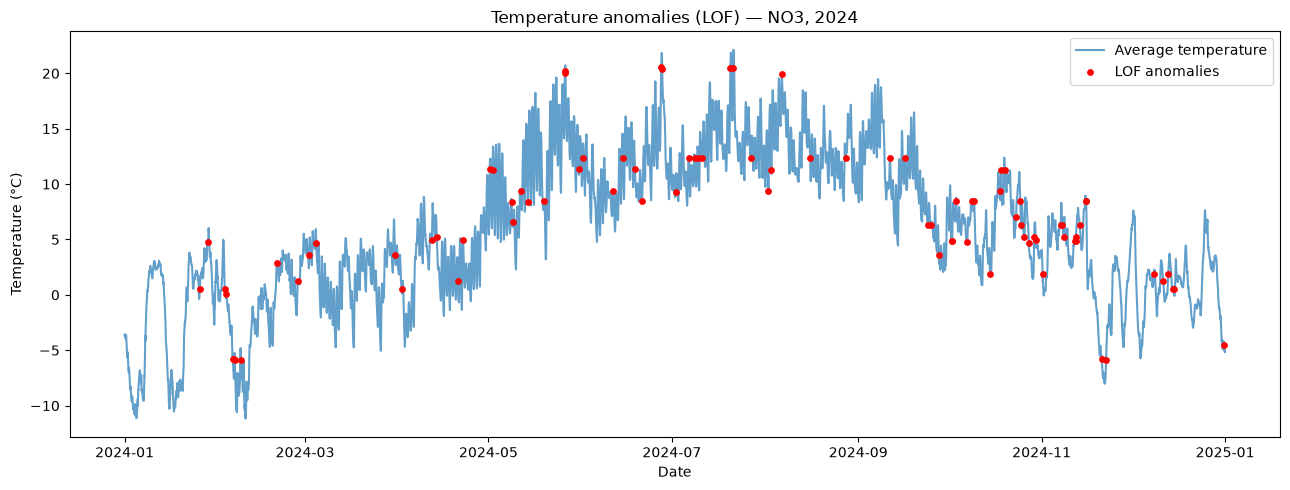

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    df_average["date"],
    temperature,
    label="Average temperature",
    alpha=0.7
)

ax.scatter(
    df_average.loc[anomalies, "date"],
    temperature[anomalies],
    color="red",
    s=15,
    label="LOF anomalies",
    zorder=3
)

ax.set_title("Temperature anomalies (LOF) — NO3, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()

plt.tight_layout()
plt.show()

# LOF Function

In [ ]:
def temperature_lof(df, contamination=0.01):
    """
    Detect temperature anomalies using Local Outlier Factor (LOF).

    Returns the plot and a summary of detected anomalies.
    """

    # Extract temperature data
    temperature = df["temperature_2m"].to_numpy()
    dates = df["date"]

    # Reshape data for scikit-learn
    X = temperature.reshape(-1, 1)

    # Apply Local Outlier Factor
    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination=contamination
    )

    labels = lof.fit_predict(X)

    # Identify anomalies
    anomalies = labels == -1

    # Plot temperature and anomalies
    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        dates,
        temperature,
        label="Average temperature",
        alpha=0.7
    )

    ax.scatter(
        dates[anomalies],
        temperature[anomalies],
        color="red",
        s=15,
        label="LOF anomalies",
        zorder=3
    )

    ax.set_title("Temperature anomalies (LOF) — NO3, 2024")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()

    plt.tight_layout()

    # Anomaly summary
    summary = {
        "total_observations": len(temperature),
        "total_anomalies": int(anomalies.sum()),
        "anomaly_percentage": round(100 * anomalies.mean(), 2),
        "mean_temperature": float(np.mean(temperature)),
        "mean_anomaly_temperature": float(np.mean(temperature[anomalies]))
            if anomalies.any() else None,
        "min_anomaly_temperature": float(np.min(temperature[anomalies]))
            if anomalies.any() else None,
        "max_anomaly_temperature": float(np.max(temperature[anomalies]))
            if anomalies.any() else None
    }

    return fig, summary

{'total_observations': 8784,
 'total_anomalies': 88,
 'anomaly_percentage': np.float64(1.0),
 'mean_temperature': 5.799082279205322,
 'mean_anomaly_temperature': 6.903907299041748,
 'min_anomaly_temperature': -5.8913655281066895,
 'max_anomaly_temperature': 20.603134155273438}

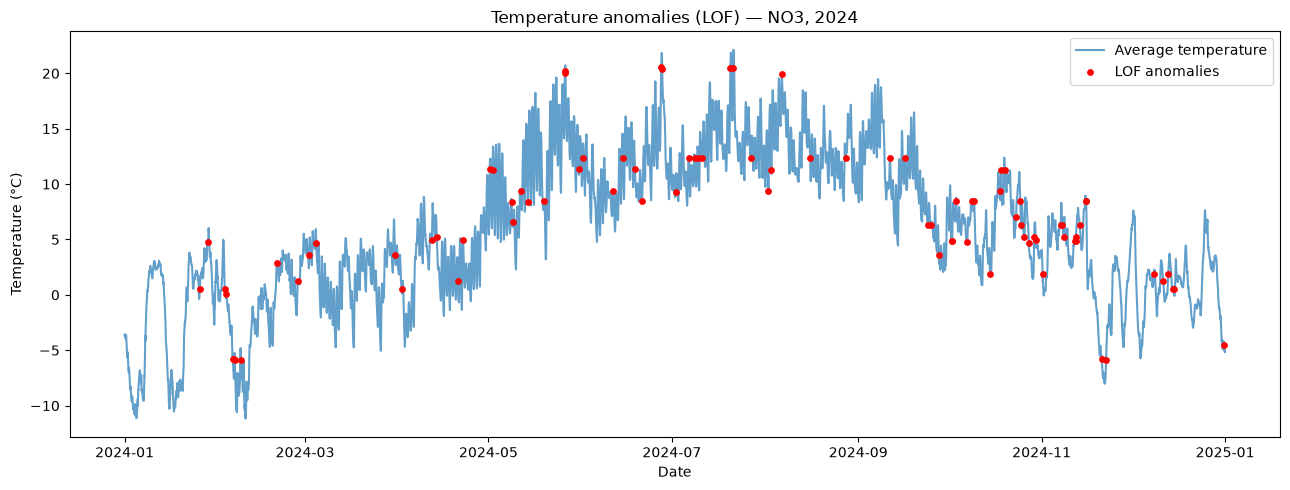

In [ ]:
fig, summary = temperature_lof(df_average)

display(summary)
plt.show()

# Testing LOF function


In [ ]:
# Test default parameters
fig, summary = temperature_lof(df_average)

assert isinstance(fig, plt.Figure)

assert summary["total_observations"] == len(df_average)

assert 0 <= summary["anomaly_percentage"] <= 100

assert summary["total_anomalies"] <= summary["total_observations"]

assert abs(summary["anomaly_percentage"] - 1.0) < 0.2

plt.close(fig)

# Test different contamination values
fig_1, summary_1 = temperature_lof(df_average, contamination=0.01)
fig_5, summary_5 = temperature_lof(df_average, contamination=0.05)

assert summary_5["total_anomalies"] > summary_1["total_anomalies"]

plt.close(fig_1)
plt.close(fig_5)

print("All LOF tests passed!")

All LOF tests passed!


In [ ]:
df_reservoir = load_reservoir_data()

display(df_reservoir.head())

2026-11-03 13:35:07.524 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-03 13:35:07.525 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,date,area_type,area_id,iso_year,iso_week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_prev_week,fill_level_change
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
9688,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643
11182,1995-01-08,VASS,3,1995,1,0.566906,28.155403,15.961480,0001-01-01T00:00:00,0.661432,-0.094525
14511,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349


In [ ]:
print(
    df_reservoir[df_reservoir["area_type"] == "EL"]["area_id"].unique()
)

[1 3 2 4 5]


In [ ]:
df_no3 = df_reservoir[
    (df_reservoir["area_type"] == "EL") &
    (df_reservoir["area_id"] == 3)
].copy()

df_no3["date"] = pd.to_datetime(df_no3["date"])
df_no3 = df_no3.sort_values("date")

# Set date as index
fill_level = df_no3.set_index("date")["fill_level"]

display(fill_level.head())

date
1995-01-08    0.602376
1995-01-15    0.569943
1995-01-22    0.542203
1995-01-29    0.508148
1995-02-05    0.473883
Name: fill_level, dtype: float64

In [ ]:
print("Observations:", len(fill_level))
print("Date range:", fill_level.index.min(), "to", fill_level.index.max())
print("Missing values:", fill_level.isna().sum())

print("\nTime intervals:")
print(fill_level.index.to_series().diff().value_counts().head())

Observations: 1660
Date range: 1995-01-08 00:00:00 to 2026-10-25 00:00:00
Missing values: 0

Time intervals:
date
7 days    1659
Name: count, dtype: int64


In [ ]:
def reservoir_stl(fill_level, seasonal=13, trend=105, robust=True):
    """
    Decompose weekly reservoir filling levels using STL.

    Returns the decomposition plot and the STL result.
    """

    stl = STL(
        fill_level,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    fig = result.plot()
    fig.set_size_inches(13, 8)
    fig.suptitle("STL Decomposition — NO3 Reservoir Filling Levels")

    fig.tight_layout()

    return fig, result

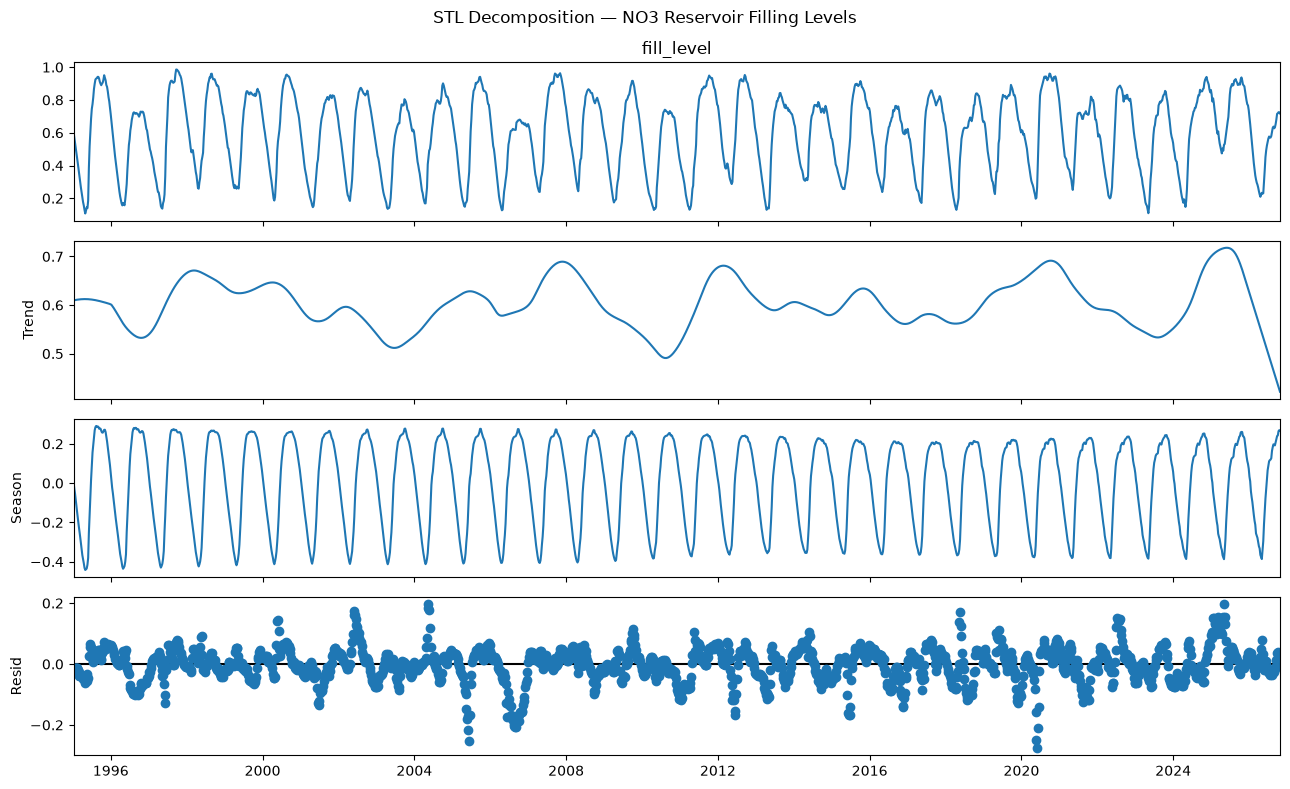

In [ ]:
fig, result = reservoir_stl(fill_level)

plt.show()

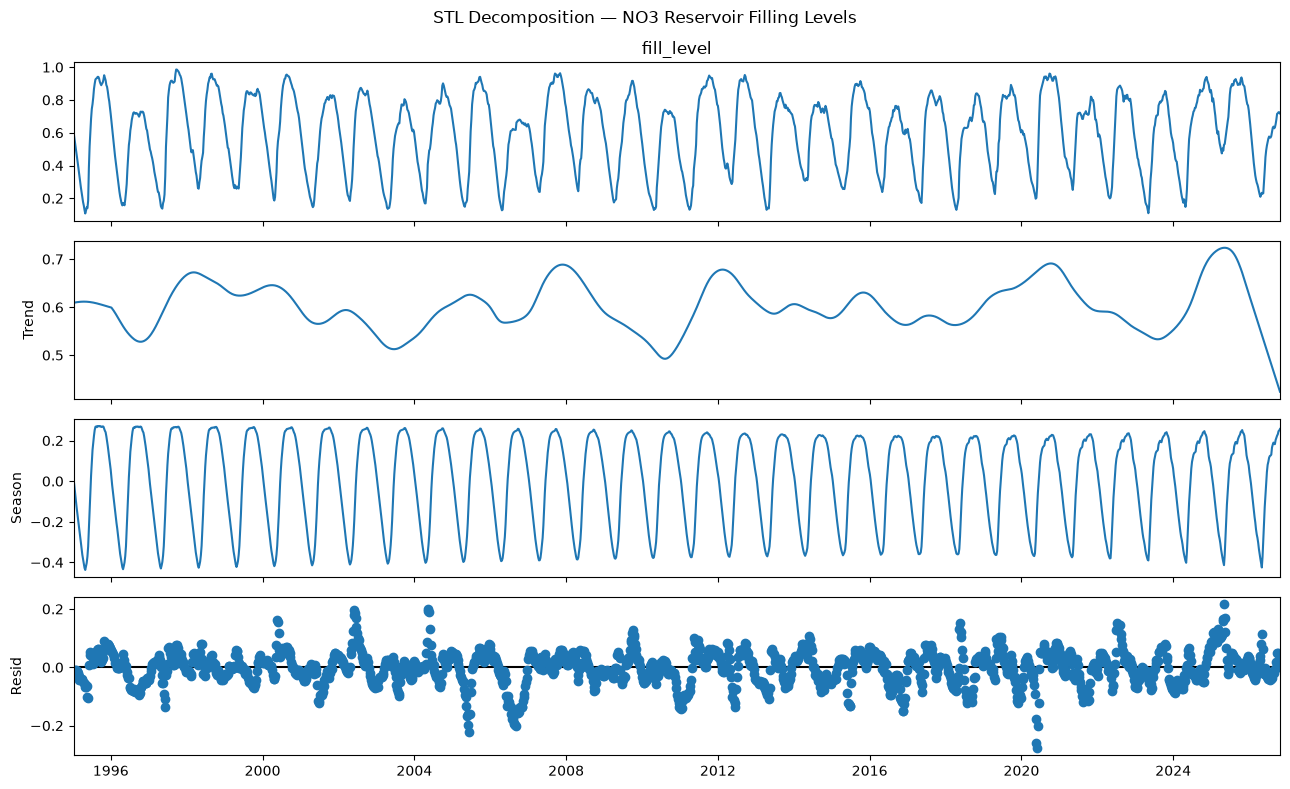

In [ ]:
fig, result = reservoir_stl(
    fill_level,
    seasonal=25,
    trend=105,
    robust=True
)

plt.show()

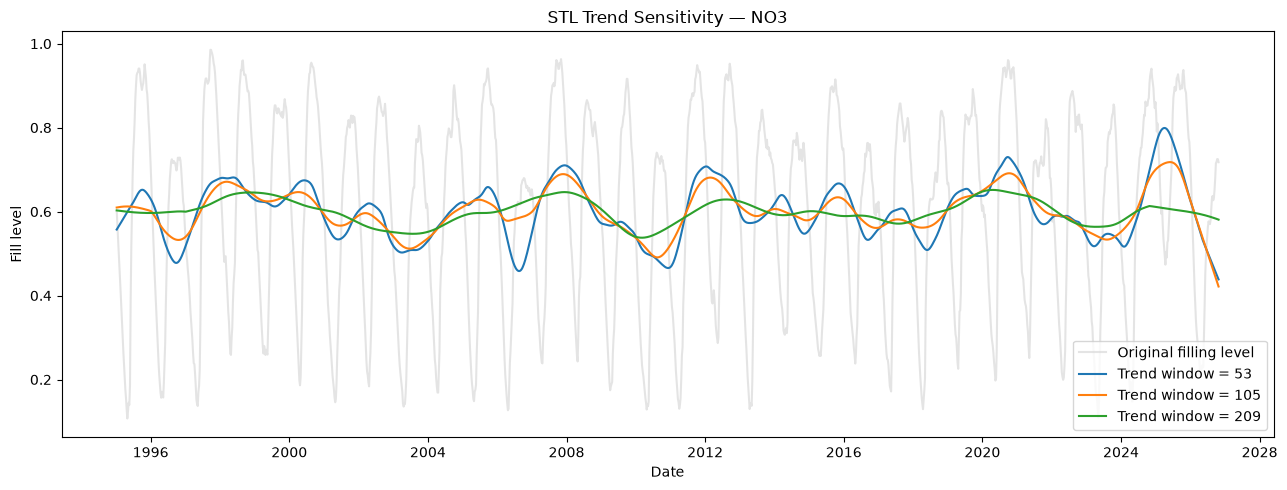

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    fill_level.index,
    fill_level,
    color="lightgray",
    alpha=0.6,
    label="Original filling level"
)

for window in [53, 105, 209]:
    result = STL(
        fill_level,
        period=52,
        seasonal=13,
        trend=window,
        robust=True
    ).fit()

    ax.plot(
        fill_level.index,
        result.trend,
        label=f"Trend window = {window}"
    )

ax.set_title("STL Trend Sensitivity — NO3")
ax.set_xlabel("Date")
ax.set_ylabel("Fill level")
ax.legend()

plt.tight_layout()
plt.show()

Exploring the sharp decline at the end of the trend plot, as it could be an edge case.Might indicate that trend is sensitive to the smoothing parameter at the endpoint were fewer observations are available. Wont take any actions about it right now but will be aware of it. 

# Assertion tests

In [ ]:
# Test default parameters
fig, result = reservoir_stl(fill_level)

assert isinstance(fig, plt.Figure)

assert len(result.trend) == len(fill_level)
assert len(result.seasonal) == len(fill_level)
assert len(result.resid) == len(fill_level)

# Verify that the components reconstruct the original series
reconstructed = result.trend + result.seasonal + result.resid

assert np.allclose(fill_level.to_numpy(), reconstructed)

# Check for missing values
assert not np.isnan(result.trend).any()
assert not np.isnan(result.seasonal).any()
assert not np.isnan(result.resid).any()

plt.close(fig)

# Test adjustable parameters
fig, result_2 = reservoir_stl(
    fill_level,
    seasonal=25,
    trend=105,
    robust=False
)

assert len(result_2.trend) == len(fill_level)
assert np.allclose(
    fill_level.to_numpy(),
    result_2.trend + result_2.seasonal + result_2.resid
)

plt.close(fig)

print("All STL tests passed!")

All STL tests passed!


# Creating spectrogram

In [ ]:
# Our weekly reservoir filling levels
y = fill_level.to_numpy()

#Remove mean to reduce zero-frequency component
y_centered = y - np.mean(y)

# Short-Time Fourier Transform
f, t, Zxx = stft(
    y_centered,
    fs=1,
    nperseg=208,
    noverlap=104
)

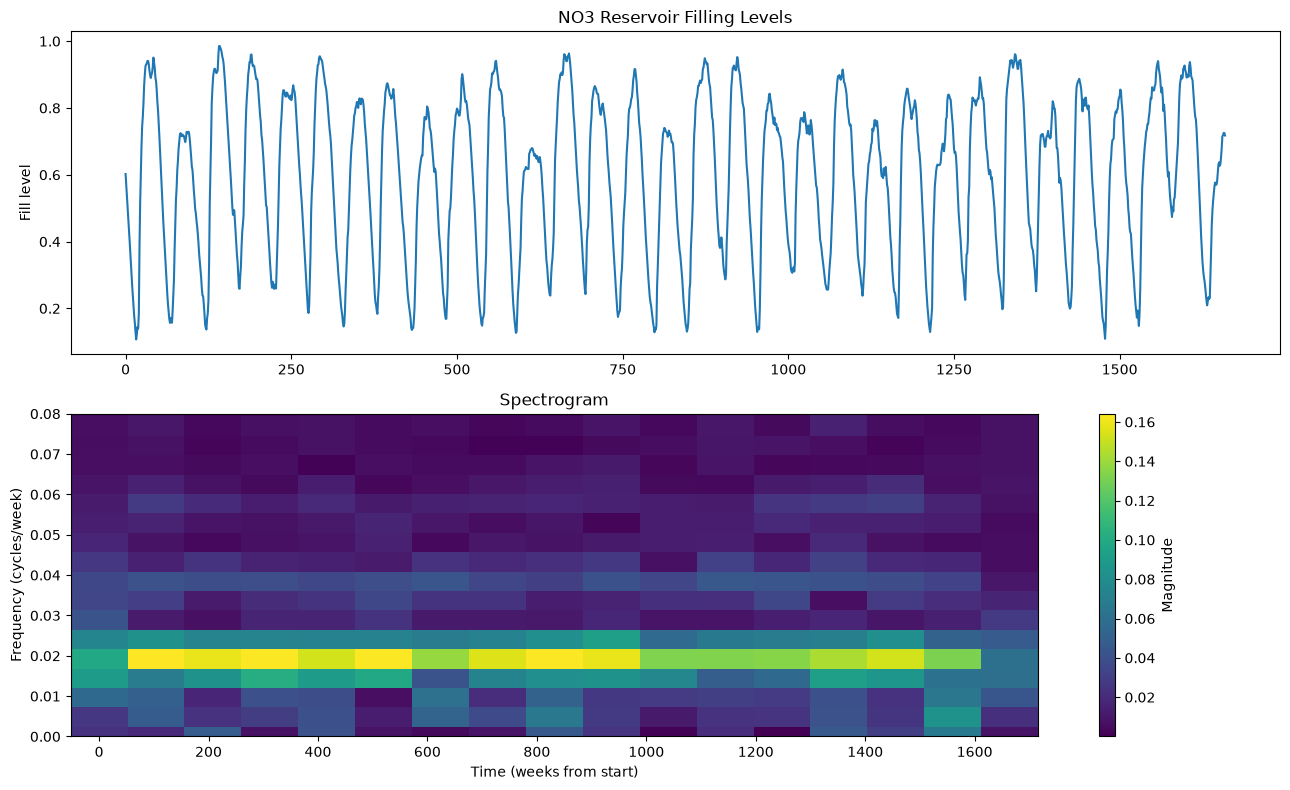

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(13, 8))

# Original time series
axs[0].plot(np.arange(len(y)), y)
axs[0].set_ylabel("Fill level")
axs[0].set_title("NO3 Reservoir Filling Levels")

# Spectrogram
pcm = axs[1].pcolormesh(
    t,
    f,
    np.abs(Zxx),
    shading="auto"
)

axs[1].set_ylabel("Frequency (cycles/week)")
axs[1].set_xlabel("Time (weeks from start)")
axs[1].set_title("Spectrogram")
axs[1].set_ylim(0, 0.08) #zooming in on low-frecuency where we see the seasonal patterns.

fig.colorbar(pcm, ax=axs[1], label="Magnitude")

plt.tight_layout()
plt.show()

The spectrogram shows a strong and persistent frequency component around 0.02 cycles/week, corresponding to an annual cycle of approximately 52 weeks. This supports the seasonal pattern identified through STL decomposition. Overall, reservoir filling levels are dominated by low-frequency variations, with relatively little high-frequency activity.

# Reusable spectogram function

In [ ]:
def reservoir_spectrogram(fill_level, nperseg=208, noverlap=104):
    """
    Create a spectrogram of weekly reservoir filling levels.

    Returns the Matplotlib figure and STFT results.
    """

    # Original reservoir data
    y = fill_level.to_numpy()

    # Remove mean for frequency analysis
    y_centered = y - np.mean(y)

    # Short-Time Fourier Transform
    f, t, Zxx = stft(
        y_centered,
        fs=1,
        nperseg=nperseg,
        noverlap=noverlap
    )

    # Create plots
    fig, axs = plt.subplots(2, 1, figsize=(13, 8))

    # Original filling levels
    axs[0].plot(np.arange(len(y)), y)
    axs[0].set_title("NO3 Reservoir Filling Levels")
    axs[0].set_ylabel("Fill level")

    # Spectrogram
    pcm = axs[1].pcolormesh(
        t,
        f,
        np.abs(Zxx),
        shading="auto"
    )

    axs[1].set_title("Spectrogram")
    axs[1].set_xlabel("Time (weeks from start)")
    axs[1].set_ylabel("Frequency (cycles/week)")

    # Focus on low frequencies
    axs[1].set_ylim(0, 0.08)

    fig.colorbar(pcm, ax=axs[1], label="Magnitude")

    plt.tight_layout()

    return fig, (f, t, Zxx)

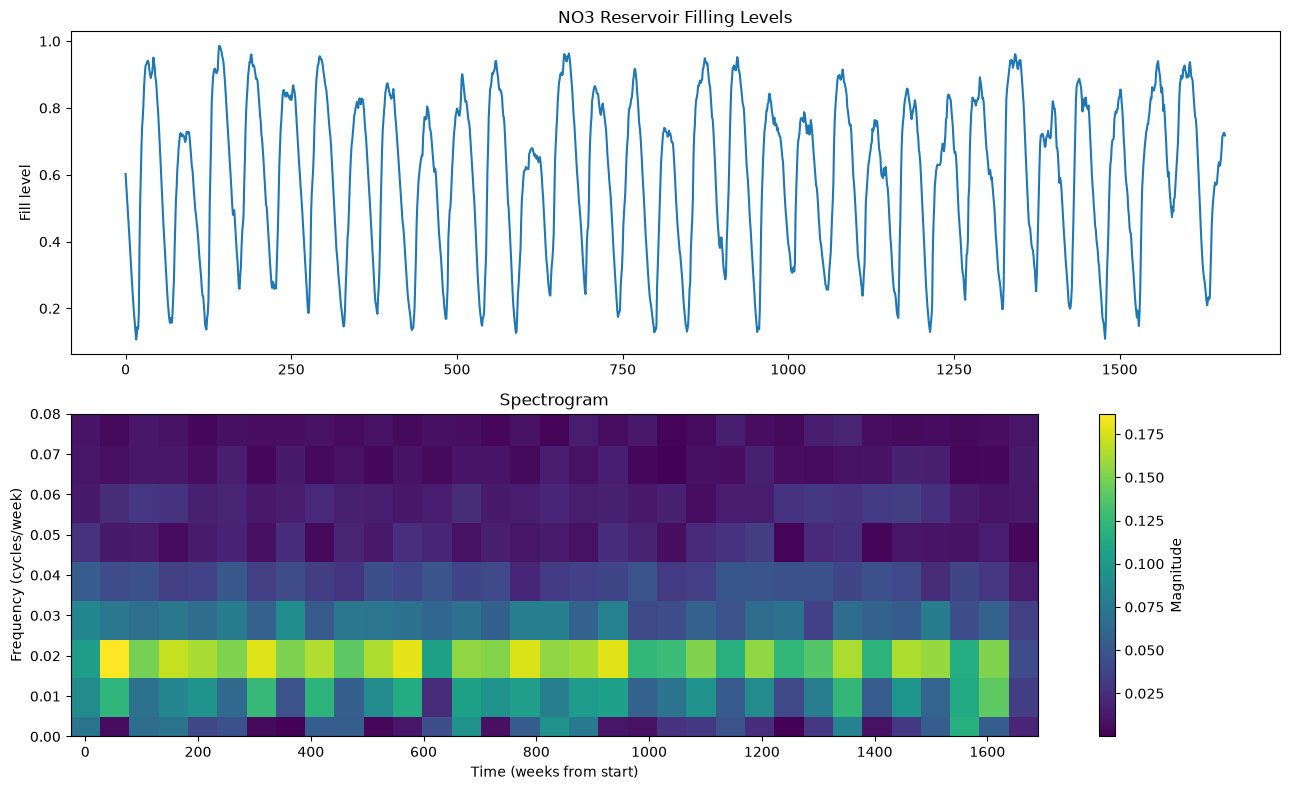

In [ ]:
fig, result = reservoir_spectrogram(
    fill_level,
    nperseg=104,
    noverlap=52
)

plt.show()

# Assertion test

In [ ]:
# Test default parameters
fig, result = reservoir_spectrogram(fill_level)

f, t, Zxx = result

assert isinstance(fig, plt.Figure)

# Frequencies, time windows and coefficients must align
assert Zxx.shape == (len(f), len(t))

# No missing or infinite Fourier coefficients
assert np.isfinite(Zxx).all()

# Frequency range for weekly observations (Nyquist frequency)
assert np.isclose(f[0], 0)
assert np.isclose(f[-1], 0.5)

# Expected number of frequency bins for a 208-week window
assert len(f) == 208 // 2 + 1

plt.close(fig)

# Test adjustable parameters
fig_2, result_2 = reservoir_spectrogram(
    fill_level,
    nperseg=104,
    noverlap=52
)

f_2, t_2, Zxx_2 = result_2

assert isinstance(fig_2, plt.Figure)
assert Zxx_2.shape == (len(f_2), len(t_2))

# Shorter window gives fewer frequency bins
assert len(f_2) < len(f)

# Shorter window and smaller step give more time windows
assert len(t_2) > len(t)

plt.close(fig_2)

print("All spectrogram tests passed!")

All spectrogram tests passed!


# AI Usage

I used ChatGPT to support me for task3, mainly with understanding statistical methods, making code and troubleshooting errors. It was used to understand DCT, SPC, LOF, STL and STFT. I also used it to develop and structure the weather data collection and processing pipeline in the jupyter notebook. Also was used a lot for troubleshooting, with API requests and file handling etc. Lastly it was used to improve readability of the code.

# Log

The first step was preparing the weather dataset. Since each region contained approximately 1,000 sampled locations, downloading everything in a single request was impractical. I therefore implemented batch downloading, saving each completed batch locally so that interrupted downloads would not require restarting the entire process. The observations were then aggregated into hourly regional averages, providing a more manageable dataset for further analysis.

Next, I worked on implementing the statistical analyses. For precipitation, I applied the Discrete Cosine Transform (DCT) together with Statistical Process Control (SPC) to investigate unusual observations. For temperature, I used Local Outlier Factor (LOF) to identify anomalies based on local differences between observations. I also extended the analysis to reservoir filling levels from Part 1, using Seasonal-Trend decomposition with LOESS (STL) to separate trend, seasonal and residual components. Finally, I implemented a spectrogram using the Short-Time Fourier Transform (STFT) to examine how frequency patterns changed over time. Throughout this process, I focused on understanding the methods and relating the implementations to the lecturer's examples.

After completing the analyses, I integrated the visualizations into the existing Streamlit application. I also organized the code and data-loading functions to make the application easier to maintain.

I decided to remove the reservoirdata page. In my opinion it does not add anything useful that you cant find from the plots.py page, and it was essentially just in the way and made the layout messier. 

Considering the meteorogical data from openmeteo: For 1000 locations it took a long time to download everything (My code took around 5 minutes just to download NO3 for 2024). So I decided to only display for NO3 and year 2024 for now. I have added the functionality to download and load in other data aswell, but i have manually overwritten it for now considering API and time limits. I also made sure that only the aggregated weather data is uploaded to GitHub because of the size of the whole dataset. 